**Install/import libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

print("Libraries loaded successfully")

Libraries loaded successfully


**Download the experimental dataset**

In [2]:
import os

repo_url = "https://github.com/EnzeXu/Damped_Pendulum_Dataset.git"

!git clone -q {repo_url}

print("Dataset downloaded.")

Dataset downloaded.


check this

In [3]:
!ls Damped_Pendulum_Dataset/cleaned_data | head -20

len1_cond1_1.csv
len1_cond1_2.csv
len1_cond1_3.csv
len1_cond2_1.csv
len1_cond2_2.csv
len1_cond2_3.csv
len1_cond3_1.csv
len1_cond3_2.csv
len1_cond3_3.csv
len2_cond1_1.csv
len2_cond1_2.csv
len2_cond1_3.csv
len2_cond2_1.csv
len2_cond2_2.csv
len2_cond2_3.csv
len2_cond3_1.csv
len2_cond3_2.csv
len2_cond3_3.csv
len3_cond1_1.csv
len3_cond1_2.csv


**Load our first experiment**

In [4]:
file_path = "Damped_Pendulum_Dataset/cleaned_data/len1_cond1_1.csv"

df = pd.read_csv(file_path)

print(df.head())
print("\nColumns:")
print(df.columns)

print("\nShape:")
print(df.shape)

   time  angle  angular_velocity  is_peak
0  0.00 -0.767             0.681        0
1  0.01 -0.757             0.995        0
2  0.02 -0.745             1.309        0
3  0.03 -0.732             1.623        0
4  0.04 -0.713             1.990        0

Columns:
Index(['time', 'angle', 'angular_velocity', 'is_peak'], dtype='object')

Shape:
(6000, 4)


**Define the physical parameters**

In [5]:
L = 0.236       # pendulum length, m
g = 9.799       # gravitational acceleration, m/s^2

t_exp = df["time"].values
theta_exp = df["angle"].values
omega_exp = df["angular_velocity"].values

print("Pendulum length =", L, "m")
print("Gravity =", g, "m/s²")
print("Number of samples =", len(t_exp))

Pendulum length = 0.236 m
Gravity = 9.799 m/s²
Number of samples = 6000


**observe the experimental system Angle variation**

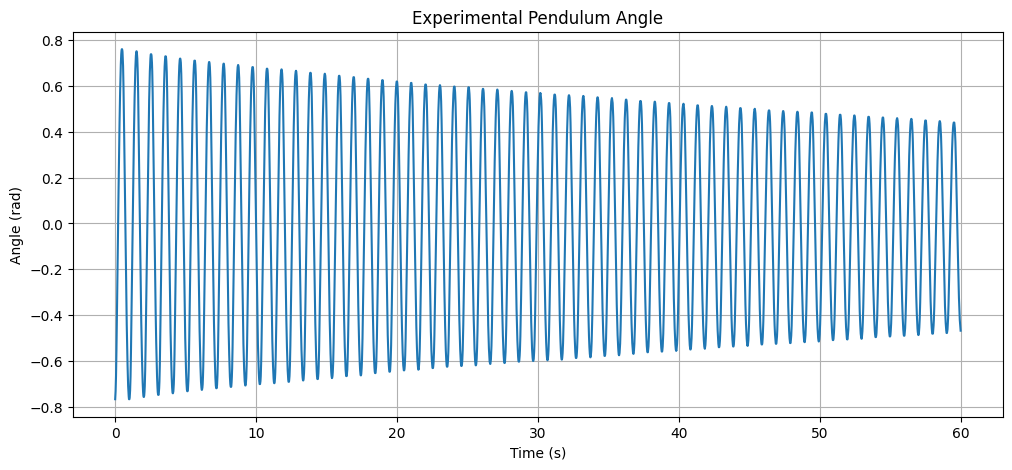

In [6]:
plt.figure(figsize=(12,5))

plt.plot(t_exp, theta_exp)

plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.title("Experimental Pendulum Angle")

plt.grid(True)
plt.show()

**Angular velocity**

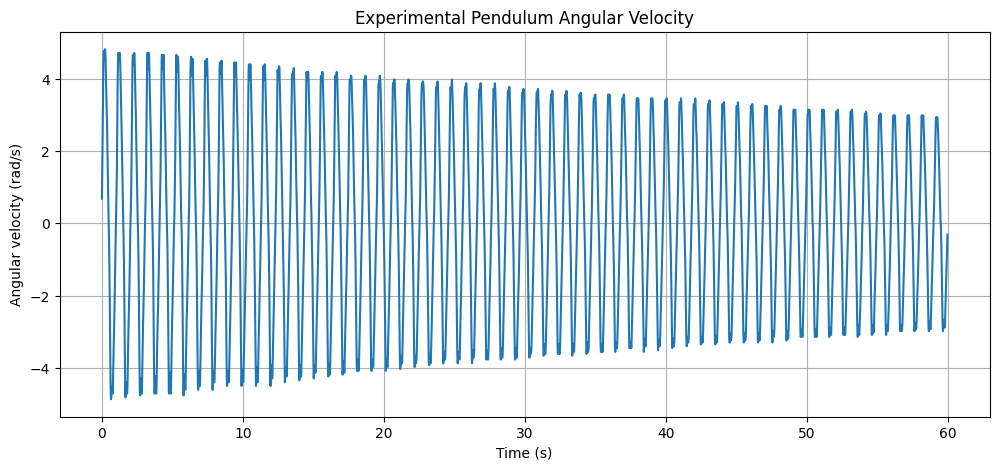

In [7]:
plt.figure(figsize=(12,5))

plt.plot(t_exp, omega_exp)

plt.xlabel("Time (s)")
plt.ylabel("Angular velocity (rad/s)")
plt.title("Experimental Pendulum Angular Velocity")

plt.grid(True)
plt.show()

**Build the actual Digital Twin**

In [8]:
def pendulum_model(t, state, b):

    theta, omega = state

    dtheta_dt = omega

    domega_dt = -(g/L) * np.sin(theta) - b * omega

    return [dtheta_dt, domega_dt]

**Run the Digital Twin Use the initial state measured by the experiment.**

In [9]:
theta0 = theta_exp[0]
omega0 = omega_exp[0]

initial_state = [theta0, omega0]

print("Initial angle =", theta0, "rad")
print("Initial angular velocity =", omega0, "rad/s")

Initial angle = -0.767 rad
Initial angular velocity = 0.681 rad/s


**Now let's temporarily assume damping coefficient b=0.1**

In [10]:
b_test = 0.1

solution = solve_ivp(
    lambda t, y: pendulum_model(t, y, b_test),
    [t_exp[0], t_exp[-1]],
    initial_state,
    t_eval=t_exp
)

theta_twin = solution.y[0]
omega_twin = solution.y[1]

**Compare it with the experiment:**

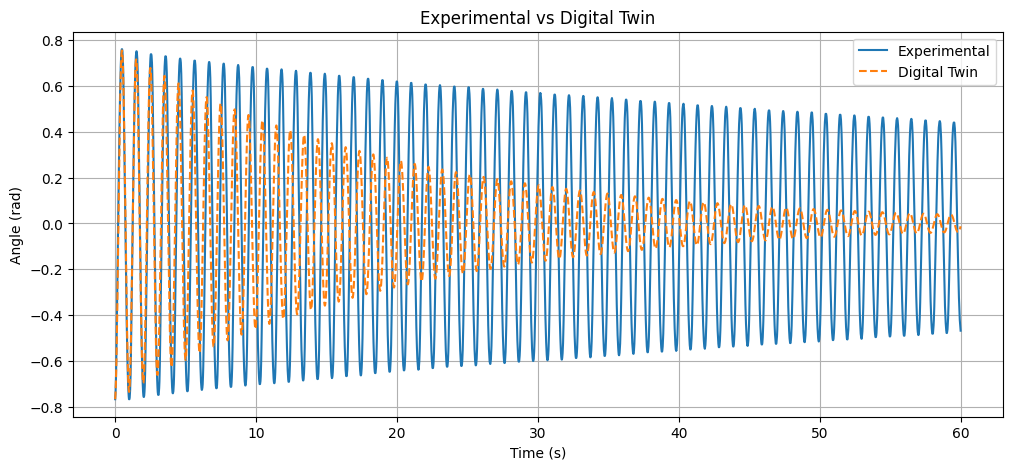

In [11]:
plt.figure(figsize=(12,5))

plt.plot(t_exp, theta_exp, label="Experimental")
plt.plot(t_exp, theta_twin, "--", label="Digital Twin")

plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.title("Experimental vs Digital Twin")

plt.legend()
plt.grid(True)
plt.show()

**Since twin and experimental data do not match Let the Digital Twin learn the damping**

In [12]:
def calculate_rmse(b):

    solution = solve_ivp(
        lambda t, y: pendulum_model(t, y, b),
        [t_exp[0], t_exp[-1]],
        initial_state,
        t_eval=t_exp
    )

    theta_model = solution.y[0]

    rmse = np.sqrt(
        np.mean((theta_exp - theta_model)**2)
    )

    return rmse

**Now optimize \(b\):**

In [13]:
result = minimize_scalar(
    calculate_rmse,
    bounds=(0, 2),
    method="bounded"
)

b_opt = result.x
rmse_opt = result.fun

print("Estimated damping coefficient =", b_opt)
print("RMSE =", rmse_opt)

Estimated damping coefficient = 0.6282652891372266
RMSE = 0.417735516808337


**Run the optimized Digital Twin**

In [14]:
solution = solve_ivp(
    lambda t, y: pendulum_model(t, y, b_opt),
    [t_exp[0], t_exp[-1]],
    initial_state,
    t_eval=t_exp
)

theta_twin = solution.y[0]
omega_twin = solution.y[1]

**Plot**

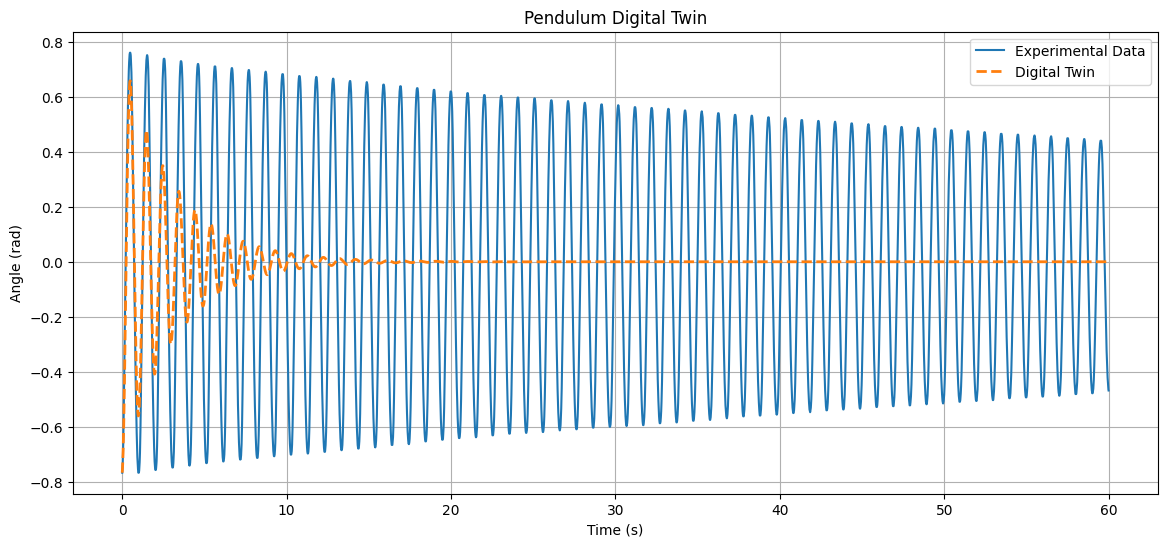

In [15]:
plt.figure(figsize=(14,6))

plt.plot(
    t_exp,
    theta_exp,
    label="Experimental Data",
    linewidth=1.5
)

plt.plot(
    t_exp,
    theta_twin,
    "--",
    label="Digital Twin",
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.title("Pendulum Digital Twin")

plt.legend()
plt.grid(True)
plt.show()

**Calculate the final error**

In [16]:
rmse_angle = np.sqrt(
    np.mean((theta_exp - theta_twin)**2)
)

mae_angle = np.mean(
    np.abs(theta_exp - theta_twin)
)

print(f"RMSE = {rmse_angle:.6f} rad")
print(f"MAE  = {mae_angle:.6f} rad")

print(f"RMSE = {np.degrees(rmse_angle):.4f} degrees")
print(f"MAE  = {np.degrees(mae_angle):.4f} degrees")

RMSE = 0.417736 rad
MAE  = 0.370221 rad
RMSE = 23.9345 degrees
MAE  = 21.2121 degrees


**Above results rating- Physics formulation: 8/10
Numerical implementation: 8/10
Parameter identification: 3/10
Digital Twin quality: 3/10**

**Errot resolution : Extract the experimental peaks**

Number of peaks: 59


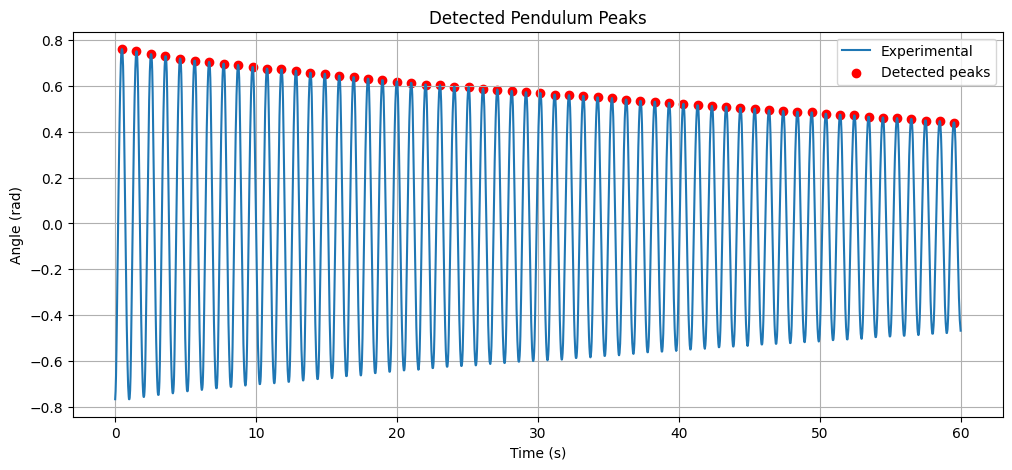

In [17]:
from scipy.signal import find_peaks
import numpy as np
import matplotlib.pyplot as plt

# Find positive peaks
peaks, properties = find_peaks(
    theta_exp,
    prominence=0.02,
    distance=50
)

peak_times = t_exp[peaks]
peak_angles = theta_exp[peaks]

print("Number of peaks:", len(peaks))

plt.figure(figsize=(12,5))

plt.plot(t_exp, theta_exp, label="Experimental")
plt.scatter(
    peak_times,
    peak_angles,
    color="red",
    label="Detected peaks"
)

plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.title("Detected Pendulum Peaks")
plt.legend()
plt.grid(True)
plt.show()

**Then calculate the damping rate**

In [18]:
from scipy.stats import linregress

# Use positive peak amplitudes
A = peak_angles

# Remove any problematic very small values
mask = A > 0

peak_times_fit = peak_times[mask]
A_fit = A[mask]

# Logarithmic decrement relationship
log_A = np.log(A_fit)

slope, intercept, r_value, p_value, std_err = linregress(
    peak_times_fit,
    log_A
)

beta = -slope
A0 = np.exp(intercept)

print("Estimated damping rate beta =", beta, "1/s")
print("Estimated initial amplitude =", A0, "rad")
print("R² =", r_value**2)

Estimated damping rate beta = 0.00886300982152865 1/s
Estimated initial amplitude = 0.745485456635566 rad
R² = 0.9982097386096404


**Therefore use:**

In [19]:
beta = 0.00886300982152865

b = 2 * beta

print("Envelope decay rate beta =", beta)
print("ODE damping coefficient b =", b)

Envelope decay rate beta = 0.00886300982152865
ODE damping coefficient b = 0.0177260196430573


**Now rebuild the Digital Twin

Use this instead of the previous optimization result**

**rebuild digital twin using new value of damping coeffcient b**

In [20]:
beta = 0.00886300982152865

# Important: for theta'' + b*theta' + (g/L)sin(theta)=0
# amplitude decays approximately as exp(-b*t/2)

b = 2 * beta

print("Damping coefficient b =", b)

Damping coefficient b = 0.0177260196430573


In [21]:
def pendulum_model(t, state):

    theta, omega = state

    dtheta_dt = omega

    domega_dt = -(g/L)*np.sin(theta) - b*omega

    return [dtheta_dt, domega_dt]

In [22]:
solution = solve_ivp(
    pendulum_model,
    [t_exp[0], t_exp[-1]],
    [theta_exp[0], omega_exp[0]],
    t_eval=t_exp,
    rtol=1e-9,
    atol=1e-11
)

theta_twin = solution.y[0]
omega_twin = solution.y[1]

**Now compare them**

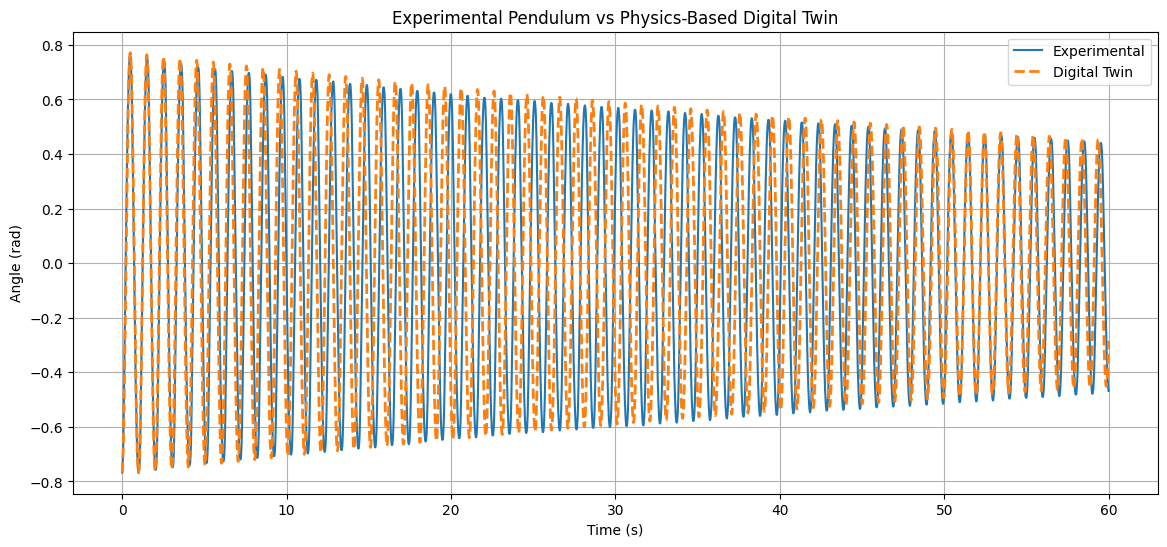

In [23]:
plt.figure(figsize=(14,6))

plt.plot(
    t_exp,
    theta_exp,
    label="Experimental",
    linewidth=1.5
)

plt.plot(
    t_exp,
    theta_twin,
    "--",
    label="Digital Twin",
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.title("Experimental Pendulum vs Physics-Based Digital Twin")

plt.legend()
plt.grid(True)
plt.show()

**Then calculate rmse mae:**

In [24]:
rmse = np.sqrt(np.mean((theta_exp - theta_twin)**2))
mae = np.mean(np.abs(theta_exp - theta_twin))

print(f"RMSE = {rmse:.6f} rad")
print(f"MAE  = {mae:.6f} rad")

print(f"RMSE = {np.degrees(rmse):.3f} degrees")
print(f"MAE  = {np.degrees(mae):.3f} degrees")

RMSE = 0.572585 rad
MAE  = 0.444698 rad
RMSE = 32.807 degrees
MAE  = 25.479 degrees


**Let's quantify the frequency instead of judging the graph**

In [25]:
from scipy.signal import find_peaks
import numpy as np

# Experimental peaks
peaks_exp, _ = find_peaks(
    theta_exp,
    prominence=0.02,
    distance=50
)

t_peaks_exp = t_exp[peaks_exp]

# Digital Twin peaks
peaks_twin, _ = find_peaks(
    theta_twin,
    prominence=0.02,
    distance=50
)

t_peaks_twin = t_exp[peaks_twin]

# Periods
T_exp = np.diff(t_peaks_exp)
T_twin = np.diff(t_peaks_twin)

print("Experimental mean period:",
      np.mean(T_exp), "s")

print("Digital Twin mean period:",
      np.mean(T_twin), "s")

print("Experimental frequency:",
      1/np.mean(T_exp), "Hz")

print("Digital Twin frequency:",
      1/np.mean(T_twin), "Hz")

Experimental mean period: 1.0177586206896552 s
Digital Twin mean period: 0.9979661016949152 s
Experimental frequency: 0.9825512451295951 Hz
Digital Twin frequency: 1.002038043478261 Hz


In [26]:
rmse = np.sqrt(
    np.mean((theta_exp - theta_twin)**2)
)

mae = np.mean(
    np.abs(theta_exp - theta_twin)
)

print("RMSE =", rmse, "rad")
print("MAE  =", mae, "rad")

print("RMSE =", np.degrees(rmse), "degrees")
print("MAE  =", np.degrees(mae), "degrees")

RMSE = 0.5725845079000771 rad
MAE  = 0.44469836536834967 rad
RMSE = 32.80667571724956 degrees
MAE  = 25.479339491973086 degrees



**compare time periods from experiment and digital twin**

In [27]:

print("First 10 experimental periods:")
print(T_exp[:10])

print("\nFirst 10 Digital Twin periods:")
print(T_twin[:10])

print("\nExperimental period:")
print(f"Mean = {np.mean(T_exp):.6f} s")
print(f"Std  = {np.std(T_exp):.6f} s")

print("\nDigital Twin period:")
print(f"Mean = {np.mean(T_twin):.6f} s")
print(f"Std  = {np.std(T_twin):.6f} s")

First 10 experimental periods:
[1.03 1.03 1.03 1.04 1.03 1.03 1.03 1.02 1.03 1.02]

First 10 Digital Twin periods:
[1.02 1.01 1.01 1.01 1.01 1.01 1.   1.01 1.01 1.01]

Experimental period:
Mean = 1.017759 s
Std  = 0.008103 s

Digital Twin period:
Mean = 0.997966 s
Std  = 0.008188 s


In [28]:
# Percentage difference in period

period_error_percent = (
    (np.mean(T_twin) - np.mean(T_exp))
    / np.mean(T_exp)
) * 100

print(
    f"Digital Twin period error = "
    f"{period_error_percent:.3f}%"
)

Digital Twin period error = -1.945%


**Small-angle theoretical period**

In [29]:

T0 = 2 * np.pi * np.sqrt(L / g)

print(f"Physical pendulum length = {L:.4f} m")
print(f"Gravity = {g:.4f} m/s²")
print(f"Small-angle theoretical period = {T0:.6f} s")
print(f"Experimental mean period = {np.mean(T_exp):.6f} s")
print(f"Digital Twin mean period = {np.mean(T_twin):.6f} s")

Physical pendulum length = 0.2360 m
Gravity = 9.7990 m/s²
Small-angle theoretical period = 0.975091 s
Experimental mean period = 1.017759 s
Digital Twin mean period = 0.997966 s


In [30]:
# Nonlinear theoretical period using initial amplitude
# Pendulum period increases with amplitude.

from scipy.integrate import quad

theta_max = np.max(np.abs(theta_exp))

k = np.sin(theta_max / 2)

T_nonlinear = (
    4 * np.sqrt(L / g) *
    quad(
        lambda phi: 1 / np.sqrt(1 - k**2 * np.sin(phi)**2),
        0,
        np.pi/2
    )[0]
)

print(f"Initial amplitude = {theta_max:.4f} rad")
print(f"Nonlinear theoretical period = {T_nonlinear:.6f} s")
print(f"Experimental period = {np.mean(T_exp):.6f} s")

Initial amplitude = 0.7670 rad
Nonlinear theoretical period = 1.012200 s
Experimental period = 1.017759 s


In [31]:
theta0 = theta_exp[0]
omega0 = omega_exp[0]

print("Initial experimental state:")
print("theta0 =", theta0)
print("omega0 =", omega0)

Initial experimental state:
theta0 = -0.767
omega0 = 0.681


In [32]:
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
import numpy as np

# Parameters
L = 0.236
g = 9.799
b = 2 * 0.00886300982152865

def pendulum_model(t, y):
    theta, omega = y

    dtheta = omega
    domega = -(g/L)*np.sin(theta) - b*omega

    return [dtheta, domega]

# Simulate only first 5 seconds
t_test = np.linspace(0, 5, 5001)

solution_test = solve_ivp(
    pendulum_model,
    [0, 5],
    [theta0, omega0],
    t_eval=t_test,
    rtol=1e-10,
    atol=1e-12
)

theta_test = solution_test.y[0]

# Find positive peaks
peaks_test, _ = find_peaks(
    theta_test,
    prominence=0.02,
    distance=500
)

peak_times_test = t_test[peaks_test]

periods_test = np.diff(peak_times_test)

print("Peak times:")
print(peak_times_test)

print("\nPeriods:")
print(periods_test)

print("\nMean simulated period:")
print(np.mean(periods_test))

Peak times:
[0.483 1.495 2.507 3.518 4.528]

Periods:
[1.012 1.012 1.011 1.01 ]

Mean simulated period:
1.01125


**Final Digital Twin simulation**

In [33]:

solution = solve_ivp(
    pendulum_model,
    [t_exp[0], t_exp[-1]],
    [theta_exp[0], omega_exp[0]],
    t_eval=t_exp,
    rtol=1e-10,
    atol=1e-12
)

theta_twin = solution.y[0]
omega_twin = solution.y[1]

In [34]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

rmse = np.sqrt(mean_squared_error(theta_exp, theta_twin))
mae = mean_absolute_error(theta_exp, theta_twin)

print(f"RMSE = {rmse:.6f} rad")
print(f"MAE  = {mae:.6f} rad")

print(f"RMSE = {np.degrees(rmse):.2f} degrees")
print(f"MAE  = {np.degrees(mae):.2f} degrees")

RMSE = 0.572585 rad
MAE  = 0.444698 rad
RMSE = 32.81 degrees
MAE  = 25.48 degrees


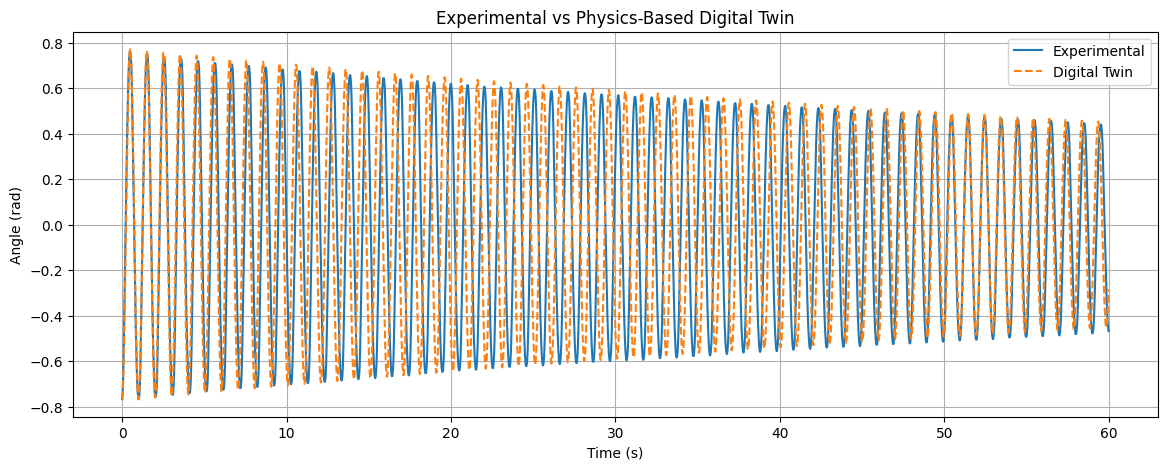

In [35]:
plt.figure(figsize=(14,5))

plt.plot(t_exp, theta_exp, label="Experimental")
plt.plot(t_exp, theta_twin, "--", label="Digital Twin")

plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.title("Experimental vs Physics-Based Digital Twin")
plt.legend()
plt.grid(True)
plt.show()

**validating digital twin model for second condition**

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Run 2 experimental data
run2_path = "/content/Damped_Pendulum_Dataset/cleaned_data/len1_cond1_2.csv"

df2 = pd.read_csv(run2_path)

t2 = df2["time"].values
theta2 = df2["angle"].values
omega2 = df2["angular_velocity"].values

print(df2.head())
print("\nNumber of samples:", len(df2))
print("Time range:", t2[0], "to", t2[-1], "s")
print("Initial angle:", theta2[0], "rad")
print("Initial angular velocity:", omega2[0], "rad/s")

   time  angle  angular_velocity  is_peak
0  0.00  0.961             0.000        0
1  0.01  0.961            -0.209        0
2  0.02  0.958            -0.419        0
3  0.03  0.952            -0.681        0
4  0.04  0.946            -0.995        0

Number of samples: 6000
Time range: 0.0 to 59.99 s
Initial angle: 0.961 rad
Initial angular velocity: 0.0 rad/s


In [37]:
L = 0.236
g = 9.799
b = 0.0177260196430573

print("Digital Twin parameters")
print("-----------------------")
print("L =", L, "m")
print("g =", g, "m/s²")
print("b =", b, "s⁻¹")

Digital Twin parameters
-----------------------
L = 0.236 m
g = 9.799 m/s²
b = 0.0177260196430573 s⁻¹


In [38]:
from scipy.integrate import solve_ivp

def pendulum_model(t, y):
    theta, omega = y

    dtheta = omega
    domega = -(g/L) * np.sin(theta) - b * omega

    return [dtheta, domega]


solution2 = solve_ivp(
    pendulum_model,
    [t2[0], t2[-1]],
    [theta2[0], omega2[0]],
    t_eval=t2,
    rtol=1e-10,
    atol=1e-12
)

theta2_twin = solution2.y[0]
omega2_twin = solution2.y[1]

print("Run 2 Digital Twin simulation completed.")

Run 2 Digital Twin simulation completed.


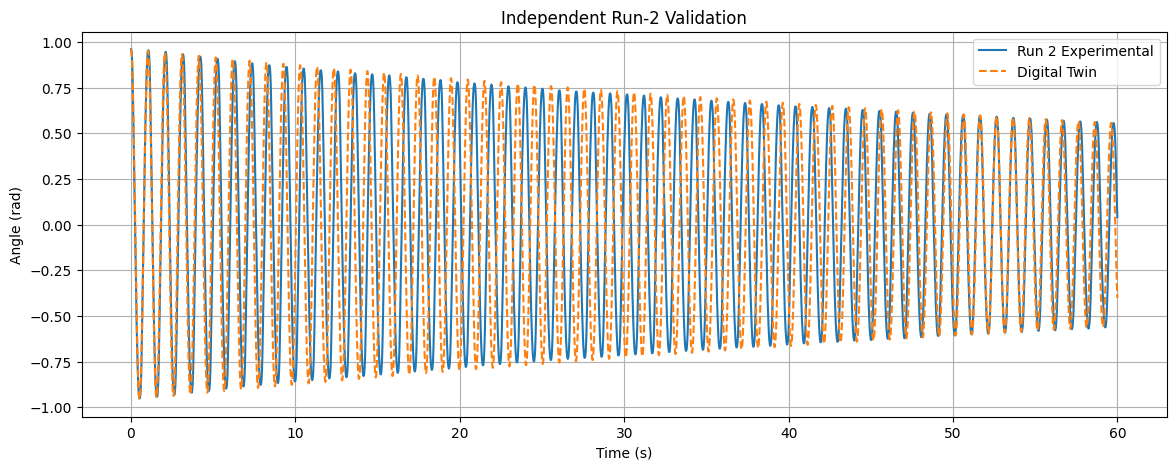

In [39]:
plt.figure(figsize=(14,5))

plt.plot(
    t2,
    theta2,
    label="Run 2 Experimental"
)

plt.plot(
    t2,
    theta2_twin,
    "--",
    label="Digital Twin"
)

plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.title("Independent Run-2 Validation")
plt.legend()
plt.grid(True)

plt.show()

In [40]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

rmse2 = np.sqrt(
    mean_squared_error(theta2, theta2_twin)
)

mae2 = mean_absolute_error(
    theta2,
    theta2_twin
)

print("Run 2 Validation")
print("----------------")
print(f"RMSE = {rmse2:.6f} rad")
print(f"MAE  = {mae2:.6f} rad")

print(f"RMSE = {np.degrees(rmse2):.2f} degrees")
print(f"MAE  = {np.degrees(mae2):.2f} degrees")

Run 2 Validation
----------------
RMSE = 0.715476 rad
MAE  = 0.557642 rad
RMSE = 40.99 degrees
MAE  = 31.95 degrees


In [41]:
from scipy.signal import find_peaks

# Experimental peaks
peaks_exp2, _ = find_peaks(
    theta2,
    prominence=0.02,
    distance=500
)

# Digital Twin peaks
peaks_twin2, _ = find_peaks(
    theta2_twin,
    prominence=0.02,
    distance=500
)

t_peaks_exp2 = t2[peaks_exp2]
t_peaks_twin2 = t2[peaks_twin2]

T_exp2 = np.diff(t_peaks_exp2)
T_twin2 = np.diff(t_peaks_twin2)

print("Run 2 Experimental period")
print(f"Mean = {np.mean(T_exp2):.6f} s")
print(f"Std  = {np.std(T_exp2):.6f} s")

print("\nRun 2 Digital Twin period")
print(f"Mean = {np.mean(T_twin2):.6f} s")
print(f"Std  = {np.std(T_twin2):.6f} s")

print("\nFrequencies")
print(f"Experimental = {1/np.mean(T_exp2):.6f} Hz")
print(f"Digital Twin = {1/np.mean(T_twin2):.6f} Hz")

period_error2 = (
    (np.mean(T_twin2) - np.mean(T_exp2))
    / np.mean(T_exp2)
) * 100

print(f"\nPeriod error = {period_error2:.3f}%")

Run 2 Experimental period
Mean = 5.152727 s
Std  = 0.056904 s

Run 2 Digital Twin period
Mean = 5.144545 s
Std  = 0.265616 s

Frequencies
Experimental = 0.194072 Hz
Digital Twin = 0.194381 Hz

Period error = -0.159%


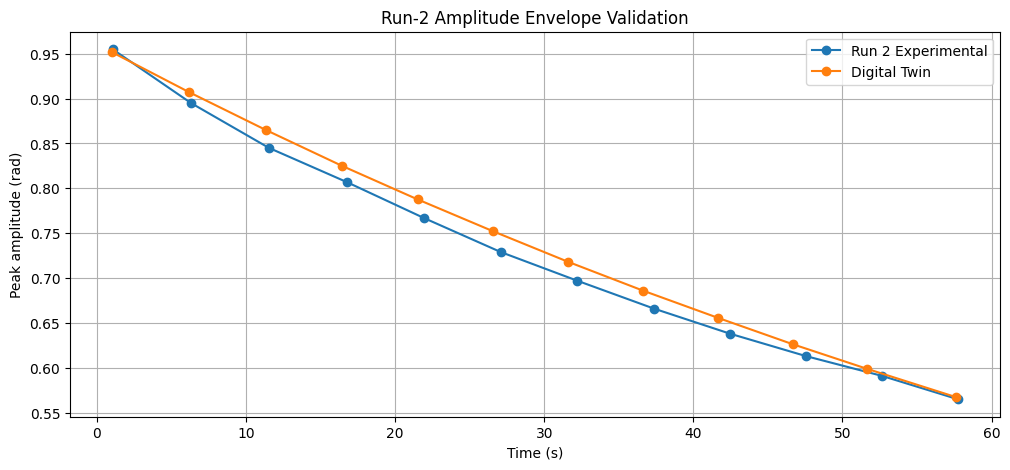

In [42]:
# Experimental peak amplitudes
amp_exp2 = np.abs(theta2[peaks_exp2])

# Digital Twin peak amplitudes
amp_twin2 = np.abs(theta2_twin[peaks_twin2])

plt.figure(figsize=(12,5))

plt.plot(
    t_peaks_exp2,
    amp_exp2,
    "o-",
    label="Run 2 Experimental"
)

plt.plot(
    t_peaks_twin2,
    amp_twin2,
    "o-",
    label="Digital Twin"
)

plt.xlabel("Time (s)")
plt.ylabel("Peak amplitude (rad)")
plt.title("Run-2 Amplitude Envelope Validation")

plt.legend()
plt.grid(True)

plt.show()